# Hands-On Online Retail Data Analysis

## Task 2: Hands-On Data Lab Implementation

This project performs practical data analysis on the UCI Online Retail dataset using Python and Jupyter Notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(5268)

In [8]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)

Duplicates removed successfully!
New dataset shape: (536641, 8)


In [9]:
cancelled = df['InvoiceNo'].astype(str).str.startswith('C').sum()

print("Number of cancelled transactions:", cancelled)

Number of cancelled transactions: 9251


In [10]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

print("Cancelled transactions removed successfully!")
print("New dataset shape:", df.shape)

Cancelled transactions removed successfully!
New dataset shape: (527390, 8)


In [11]:
df['Quantity'].min()

np.int64(-9600)

In [12]:
(df['Quantity'] <= 0).sum()

np.int64(1336)

In [13]:
df = df[df['Quantity'] > 0]

print("Invalid quantity rows removed!")
print("New dataset shape:", df.shape)

Invalid quantity rows removed!
New dataset shape: (526054, 8)


In [14]:
df['UnitPrice'].min()

np.float64(-11062.06)

In [15]:
(df['UnitPrice'] <= 0).sum()

np.int64(1176)

In [16]:
df = df[df['UnitPrice'] > 0]

print("Invalid price rows removed!")
print("New dataset shape:", df.shape)

Invalid price rows removed!
New dataset shape: (524878, 8)


In [17]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

print("Revenue column created successfully!")

Revenue column created successfully!


In [18]:
df[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [19]:
print("Total Revenue:", df['Revenue'].sum())
print("Average Transaction Revenue:", df['Revenue'].mean())
print("Maximum Transaction Revenue:", df['Revenue'].max())
print("Minimum Transaction Revenue:", df['Revenue'].min())
print("Total Quantity Sold:", df['Quantity'].sum())

Total Revenue: 10642110.804000001
Average Transaction Revenue: 20.275398862211794
Maximum Transaction Revenue: 168469.6
Minimum Transaction Revenue: 0.001
Total Quantity Sold: 5572420


In [20]:
country_transactions = df['Country'].value_counts().head(10)

country_transactions

Country
United Kingdom    479985
Germany             9025
France              8392
EIRE                7879
Spain               2479
Netherlands         2359
Belgium             2031
Switzerland         1958
Portugal            1492
Australia           1181
Name: count, dtype: int64

In [21]:
country_revenue = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)

country_revenue.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [22]:
product_quantity = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False)

product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [23]:
product_revenue = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False)

product_revenue.head(10)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

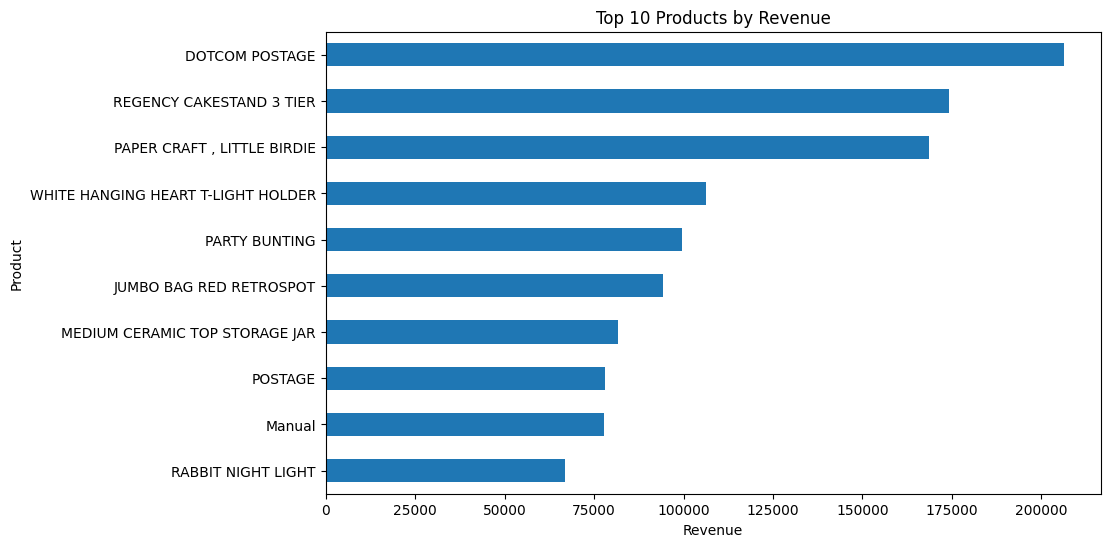

In [24]:
top_products = product_revenue.head(10).sort_values()

plt.figure(figsize=(10,6))
top_products.plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.show()

In [25]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_revenue = df.groupby('Month')['Revenue'].sum()

monthly_revenue

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

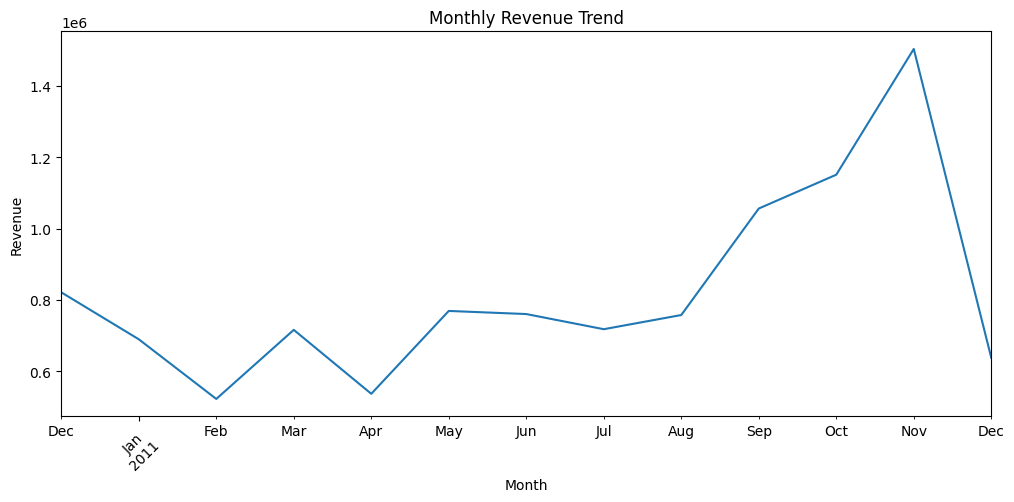

In [26]:
plt.figure(figsize=(12,5))

monthly_revenue.plot()

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

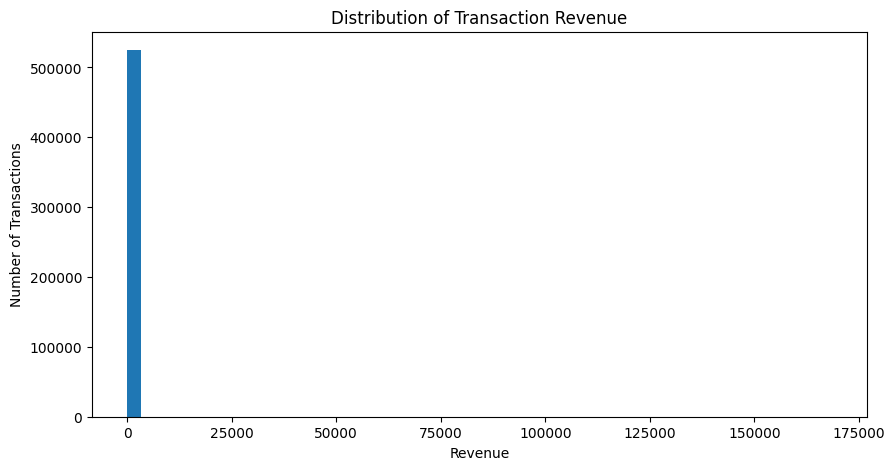

In [28]:
plt.figure(figsize=(10,5))

plt.hist(df['Revenue'], bins=50)

plt.title('Distribution of Transaction Revenue')
plt.xlabel('Revenue')
plt.ylabel('Number of Transactions')

plt.show()

In [29]:
numeric_data = df[['Quantity', 'UnitPrice', 'Revenue']]

numeric_data.corr()

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.003788,0.907402
UnitPrice,-0.003788,1.000000,0.137381
Revenue,0.907402,0.137381,1.000000


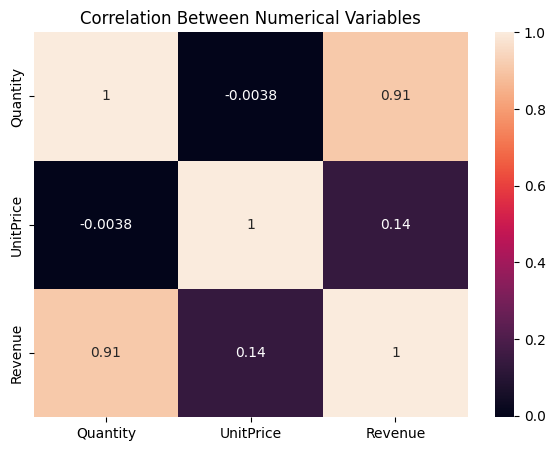

In [30]:
plt.figure(figsize=(7,5))

sns.heatmap(numeric_data.corr(), annot=True)

plt.title('Correlation Between Numerical Variables')

plt.show()

## Key Findings

- The cleaned dataset contains 524,878 valid transactions.
- The total revenue generated was approximately ₹10.64 million.
- The United Kingdom had the highest number of transactions and generated the highest revenue.
- DOTCOM POSTAGE was the highest-revenue entry, followed by REGENCY CAKESTAND 3 TIER and PAPER CRAFT, LITTLE BIRDIE.
- November 2011 recorded the highest monthly revenue of approximately ₹1.50 million.
- Revenue was highly right-skewed, meaning most transactions had relatively low revenue while a small number had very high revenue.
- Quantity and Revenue showed a strong positive correlation of approximately 0.91.
- Quantity and UnitPrice showed almost no linear relationship, with a correlation of approximately -0.0038.
- UnitPrice and Revenue showed a weak positive correlation of approximately 0.14.

## Conclusion

This project successfully demonstrated the practical use of Python and Jupyter Notebook for data analysis. The UCI Online Retail dataset was explored, cleaned, and analyzed to identify useful business insights. Duplicate records, cancelled transactions, invalid quantities, and invalid prices were handled during data cleaning. A Revenue column was created using Quantity and UnitPrice.

The analysis showed that the United Kingdom had the highest number of transactions and revenue. November 2011 recorded the highest monthly revenue. Product-level analysis identified the top revenue-generating entries, while visualizations helped understand product performance and monthly sales trends. The correlation analysis also showed a strong positive relationship between Quantity and Revenue.

Overall, this project provided practical experience in data cleaning, data manipulation, statistical analysis, visualization, and interpretation using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn.

## Data Cleaning Summary

The dataset was cleaned before performing the analysis. The following preprocessing steps were performed:

1. Duplicate records were identified and removed.
2. Cancelled transactions were identified using InvoiceNo values beginning with "C" and removed.
3. Transactions with Quantity less than or equal to zero were removed.
4. Transactions with UnitPrice less than or equal to zero were removed.
5. A new Revenue column was created using Quantity × UnitPrice.
6. InvoiceDate was converted into a proper date format for monthly analysis.
7. Missing Description and CustomerID values were identified. CustomerID was not required for the main sales analysis, while rows with missing Description were naturally excluded from product-level grouping.

## Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- UCI Online Retail Dataset